In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import sys

sys.path.append(r"/content/drive/MyDrive/Smart Gate")

In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.6/46.6 kB 2.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.7/77.7 kB 5.2 MB/s eta 0:00:00


In [ ]:
!pip install lightning

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 849.3/849.3 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 853.0/853.0 kB 42.7 MB/s eta 0:00:00


In [ ]:
from Src.data import data_acess, data_management, data_module
from Src.utils import visualizer


In [ ]:
images_path = r"C:\Users\FGstotre\Downloads\Smart Gate\Data\raw\Trucks\images"
labels_path = r"C:\Users\FGstotre\Downloads\Smart Gate\Data\raw\Trucks\labels"


dataset = data_acess.Dataset(images_dir=images_path, labels_dir=labels_path, transform=None)


image, target = dataset[1740]

print("Image size:", image.size)
print("Target Output:", target)
# Print the total number of samples in the dataset.
print(f'Number of samples in the dataset: {len(dataset)}\n')

Image size: (576, 1024)
Target Output: {'boxes': tensor([[0.7297, 0.5050, 0.5406, 0.4059],
        [0.3259, 0.5835, 0.4101, 0.1003]]), 'labels': tensor([0, 0])}
Number of samples in the dataset: 1741



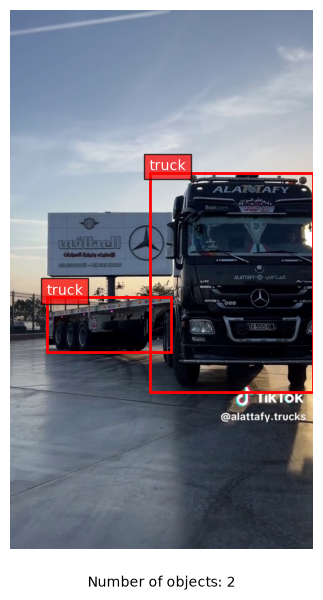

In [ ]:
visualizer.plot_img(
    image,
    target,
    info=f"Number of objects: {len(target['labels'])}"
)

## Data Splitting

In [ ]:
import os
import shutil
import random
from pathlib import Path
from sklearn.model_selection import train_test_split


# Setting up paths (adjust the base path if it differs)
BASE_DIR = Path(r"C:\Users\FGstotre\Downloads\Smart Gate\Data\raw\Trucks")
IMAGES_DIR = BASE_DIR / "images"
LABELS_DIR = BASE_DIR / "labels"

# The new path where the split data will be stored
OUTPUT_DIR = Path(r"C:\Users\FGstotre\Downloads\Smart Gate\Data\processed\Trucks")

# Reading file names and verifying they match
image_files = [
    f for f in os.listdir(IMAGES_DIR)
    if f.endswith(('.jpg', '.png', '.jpeg'))]

image_stems = [Path(f).stem for f in image_files]

# Ensure that every image has a label.
valid_stems = []

for stem in image_stems:
    label_path = LABELS_DIR / f"{stem}.txt"

    if label_path.exists():
        valid_stems.append(stem)
    else:
        print(f"Warning: Missing label for image {stem}")

print(f"Total valid image-label pairs found: {len(valid_stems)}")


# Data Splitting (90% Train, 10% Val)
train_stems, val_stems = train_test_split(valid_stems, test_size=0.10, random_state=42)

print(f"Train: {len(train_stems)} | Val: {len(val_stems)}")

# Moving files to the new folders
def copy_files(stems, split_name):


    split_dir = OUTPUT_DIR / split_name

    split_images_dir = split_dir / "images"
    split_labels_dir = split_dir / "labels"

    split_images_dir.mkdir(parents=True, exist_ok=True)
    split_labels_dir.mkdir(parents=True, exist_ok=True)

    for stem in stems:

        # Finding the original image extension
        img_name = next(
            f for f in image_files
            if Path(f).stem == stem)

        # Copy image
        shutil.copy(IMAGES_DIR / img_name, split_images_dir / img_name)

        # Copying the Label
        shutil.copy(LABELS_DIR / f"{stem}.txt", split_labels_dir / f"{stem}.txt")


print("Copying Train files...")
copy_files(train_stems, "train")

print("Copying Val files...")
copy_files(val_stems, "val")

print("✅ Data successfully split and saved to:", OUTPUT_DIR)

Total valid image-label pairs found: 1741
Train: 1566 | Val: 175
Copying Train files...
Copying Val files...
✅ Data successfully split and saved to: C:\Users\FGstotre\Downloads\Smart Gate\Data\processed\Trucks


## get mean std

In [ ]:
train_path = r"C:\Users\FGstotre\Downloads\Smart Gate\Data\processed\Trucks\train\images"

mean, std = data_management.get_mean_std(train_path)


print(f"Mean: {mean}, Std: {std}")

Mean: tensor([0.4577, 0.4417, 0.4550]), Std: tensor([0.2632, 0.2688, 0.2828])


## experiment best dataloader params

In [ ]:
import torch
import torchvision.transforms as transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

train_path = r"/content/drive/MyDrive/Smart Gate/Data/processed/Trucks/train/images"
labels_path = r"/content/drive/MyDrive/Smart Gate/Data/processed/Trucks/train/labels"

# Define the transformation pipeline
# The mean and std were calculated in cell '561960cd'
transform = transforms.Compose([
    transforms.ToTensor(), # Converts a PIL Image or numpy.ndarray to a FloatTensor and scales the image pixels to [0.0, 1.0]
    transforms.Normalize(mean=[0.4577, 0.4417, 0.4550], std=[0.2632, 0.2688, 0.2828]) # Normalize with calculated mean and std
])

train_dataset = data_acess.Dataset(
    images_dir=train_path,
    labels_dir=labels_path,
    transform=transform # Apply the defined transformation
)

batch_sizes = [32, 64, 128]
workers = [0, 2, 4]
results, best = data_management.experiment_best_dataloader_params(batch_sizes, workers, train_dataset, device)




--- Testing: Batch Size = 32 | Number of Workers = 0 ---


Overall Progress:   0%|          | 0/5 [00:00<?, ?it/s]


Epoch 1/5 | Time: 697.56 seconds (warm-up)
Epoch 2/5 | Time: 20.89 seconds (warm-up)
Epoch 3/5 | Time: 21.60 seconds 
Epoch 4/5 | Time: 20.74 seconds 
Epoch 5/5 | Time: 21.34 seconds 

Average execution time (avg of last 3): 21.22 seconds

Time taken: 21.2239 seconds
--- Testing: Batch Size = 32 | Number of Workers = 2 ---


Overall Progress:   0%|          | 0/5 [00:00<?, ?it/s]


Epoch 1/5 | Time: 25.48 seconds (warm-up)
Epoch 2/5 | Time: 24.07 seconds (warm-up)
Epoch 3/5 | Time: 25.61 seconds 
Epoch 4/5 | Time: 25.59 seconds 
Epoch 5/5 | Time: 26.15 seconds 

Average execution time (avg of last 3): 25.78 seconds

Time taken: 25.7844 seconds
--- Testing: Batch Size = 32 | Number of Workers = 4 ---


...

Overall Progress:   0%|          | 0/5 [00:00<?, ?it/s]


Epoch 1/5 | Time: 26.74 seconds (warm-up)
Epoch 2/5 | Time: 25.66 seconds (warm-up)
Epoch 3/5 | Time: 26.62 seconds 
Epoch 4/5 | Time: 26.55 seconds 
Epoch 5/5 | Time: 26.99 seconds 

Average execution time (avg of last 3): 26.72 seconds

Time taken: 26.7199 seconds
--- Testing: Batch Size = 128 | Number of Workers = 4 ---


Overall Progress:   0%|          | 0/5 [00:00<?, ?it/s]


Epoch 1/5 | Time: 30.48 seconds (warm-up)
Epoch 2/5 | Time: 31.52 seconds (warm-up)
Epoch 3/5 | Time: 30.22 seconds 
Epoch 4/5 | Time: 29.68 seconds 
Epoch 5/5 | Time: 29.66 seconds 

Average execution time (avg of last 3): 29.85 seconds

Time taken: 29.8522 seconds

✅ BEST COMBINATION FOUND:
Batch Size: 32
Number of Workers: 0
Average Epoch Time: 21.2239 seconds



"\n# Define the list of num_workers values to test\nworkers_to_test = [0, 2, 4, 8]\n\n\n# Run the experiment to measure the data loading time for different numbers of workers.\nworker_times = data_management.run_experiment(\n    # A unique name for this experiment, used as the filename for the cached results.\n    experiment_name='worker_times',\n    # The actual function that contains the experiment's logic.\n    experiment_fcn= data_management.experiment_workers,\n    # The parameters to iterate over; in this case, a list of worker counts.\n    cases=workers_to_test,\n    # The dataset required by the experiment function.\n    trainset= train_dataset,\n    # The computation device (e.g., 'cpu' or 'cuda') to be used.\n    device=device,\n    # If False, the function will load results from the cache if they exist.\n    # If True, it will force the experiment to run again and overwrite any old results.\n    rerun=False)\n"

In [ ]:
from pathlib import Path

data_dir = Path("/content/drive/MyDrive/Smart Gate/Data/processed/Trucks")


# Instantiate the DataModule for verification.
dm_verify = data_module.TruckDataModule(data_dir=data_dir, batch_size=32, num_workers=0)
# Set up the datasets.
dm_verify.setup()
train_loader_verify = dm_verify.train_dataloader()
val_loader_verify = dm_verify.val_dataloader()

# --- Verify the Training Set ---
print("--- Training Set ---")
print(f"Total samples in the training dataset:    {len(dm_verify.train_dataset)}")
print(f"DataLoader batch size:                    {train_loader_verify.batch_size}")
print(f"DataLoader length (number of batches):    {len(train_loader_verify)}")

# --- Verify the Validation Set ---
print("\n--- Validation Set ---")
print(f"Total samples in the validation dataset:  {len(dm_verify.val_dataset)}")
print(f"DataLoader batch size:                    {val_loader_verify.batch_size}")
print(f"DataLoader length (number of batches):    {len(val_loader_verify)}")

--- Training Set ---
Total samples in the training dataset:    1566
DataLoader batch size:                    32
DataLoader length (number of batches):    49

--- Validation Set ---
Total samples in the validation dataset:  175
DataLoader batch size:                    32
DataLoader length (number of batches):    6


Image tensor dimensions: torch.Size([3, 463, 692])
The maximum pixel value is: 1.0, and the minimum is: 0.0



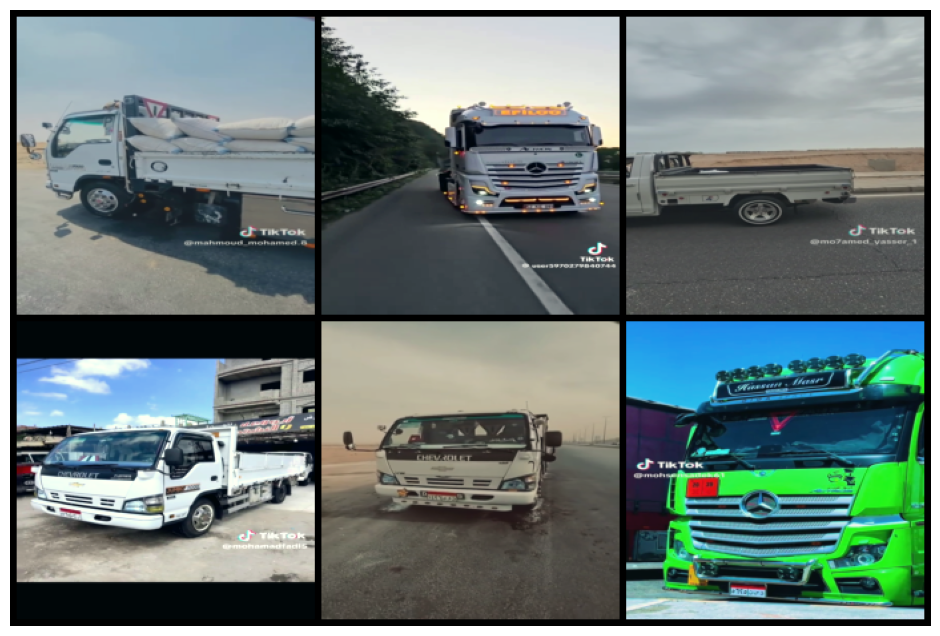

In [ ]:

import torch
import torchvision.utils as vutils
import matplotlib.pyplot as plt

# Load one batch from the training DataLoader
images, targets = next(iter(train_loader_verify))

# Convert the tuple of images into one tensor
images_tensor = torch.stack(images)

# Take only the first 6 images
images_tensor = images_tensor[:6]

# Make a grid from the loaded images
grid = vutils.make_grid(
    tensor=images_tensor,
    nrow=3,
    padding=5,
    normalize=True
)

# Check the grid dimensions and pixel values
print(f"Image tensor dimensions: {grid.shape}")
print(f"The maximum pixel value is: {grid.max()}, and the minimum is: {grid.min()}\n")

# Display the grid
plt.figure(figsize=(12, 8))
plt.imshow(grid.permute(1, 2, 0))
plt.axis("off")
plt.show()

